# 05 - E5: melhorias testadas (e registradas, inclusive as que não funcionaram)

Depois do E1 a E4 (notebook 04), este notebook testa melhorias sobre os modelos. Ele responde a duas perguntas práticas: **dá para ir além do melhor modelo do E1?** e **o quanto os números do E1 dependem de detalhes do protocolo** (vazamento por gravador, calibração)?

**Regras de rigor (as mesmas em todas as seções)**

1. **Toda escolha é feita na validação do fold 0** (480 gravações, as mesmas para todos os modelos): manter ou descartar uma técnica, hiperparâmetros, pesos do ensemble, temperatura.
2. **Uma mudança por vez**, sempre contra o **baseline equivalente do E1** (mesmo modelo, fold 0, semente 42, mesmo aumento).
3. **O teste (600 gravações) só é olhado no fim, uma vez por técnica mantida.** As técnicas descartadas na validação ficam *sem* número de teste na tabela, de propósito: olhar o teste para decidir transformaria o teste em validação.
4. Tudo vai para `resultados/e5/e5_execucoes.csv`: técnica, o que mudou, F1 de validação (baseline e técnica), F1 de teste, tempo e veredito.

**Limitação a ter em mente:** a validação do fold 0 tem 480 gravações; diferenças abaixo de ~1 ponto de F1 estão dentro do ruído de um único treino (no E1 o desvio entre folds foi dessa ordem). Por isso o veredito "mantém" exige uma melhora na validação, e as conclusões sobre ganhos pequenos são feitas com cautela.

| Seção | Técnica | Pergunta |
|---|---|---|
| 5.0 | Linha de base clássica (M0) | quanto o *deep learning* ganha sobre MFCC + classificador tradicional? |
| 5.1 | Ensemble de modelos e TTA | combinar M1, M2 e M3 ou promediar versões deslocadas da janela melhora? |
| 5.2 | Treino mais longo (M1, M2) | na Parte 1 o M1 ainda melhorava na época 30 |
| 5.3 | Divisão por gravador | quanto o F1 cai se nenhum gravador do teste aparece no treino? |
| 5.4 | Ajuste fino do M3 em duas fases | congelar o corpo no início protege o pré-treino? |
| 5.5 | M5: CNN de imagem pré-treinada | pré-treino em imagens (ImageNet) é tão bom quanto em áudio (AudioSet)? |
| 5.6 | Ajuste fino parcial do AST | cabe em 4 GB? |
| 5.7 | Calibração | as probabilidades do melhor modelo são confiáveis? |
| 5.8 | Técnicas no M1: *label smoothing*, destilação do M3, PCEN | regularização, transferência de conhecimento e representação de entrada ajudam a CNN pequena? |
| 5.9 | **M6: a CNN do projeto** | juntando, numa CNN do porte do M1, as peças que os nossos resultados indicaram, até onde ela chega? |

**Escolha do que testar (e cortes registrados na tabela):** cada treino do M3 leva ~50 min numa RTX 3050. Em vez de gastar ~4 h variando hiperparâmetros do mesmo M3 (uma única técnica no modelo mais caro), priorizamos **técnicas de famílias diferentes**, testadas no M1 (~10 min cada) quando não são específicas de pré-treino: regularização (*label smoothing*), transferência (destilação), representação de entrada (PCEN), agregação, além de arquitetura (M0, M5, AST parcial), robustez (divisão por gravador) e calibração. No M3 ficou só o ajuste em duas fases, que é próprio de modelos pré-treinados. Ficaram de fora, registrados como "não executado": M3 com *label smoothing*, M3 com lr do corpo 3e-5 e 3e-4, e M3 na divisão por gravador.

In [1]:
import os, sys, json, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display, Image
from birdclef import melhorias as mh, experimentos_p2 as e, treino, graficos, finais
from birdclef.experimentos import PASTA_CHECKPOINTS, carregar_checkpoint
%matplotlib inline
pd.set_option("display.precision", 3)
FIG = Path("resultados/e5"); FIG.mkdir(parents=True, exist_ok=True)

e1 = pd.read_csv("resultados/e1/e1_execucoes.csv").query("fold == 0").set_index("modelo")
base = e1[["val_f1_macro", "teste_f1_macro", "minutos"]].reindex(e.MODELOS)
base.columns = ["F1 val. (fold 0)", "F1 teste", "min de treino"]
print("Baselines do E1 (fold 0, semente 42): o ponto de comparação de cada técnica")
display(base.round(3))

Baselines do E1 (fold 0, semente 42): o ponto de comparação de cada técnica


,F1 val. (fold 0),F1 teste,min de treino
modelo,,,
M1,0.858,0.879,9.978
M2,0.848,0.869,8.012
M3,0.923,0.939,50.061
M4,0.839,0.823,0.126


## 5.0 Linha de base clássica: MFCC + classificador tradicional (M0)

**O que:** um modelo sem rede neural, só com processamento de sinais. De cada janela de 5 s saem 104 características calculadas sobre o mesmo log-Mel das redes: 20 MFCC (a DCT do log-Mel) e seus deltas, com média e desvio no tempo; centroide, largura de banda, *rolloff* de 85% e *flatness* do espectro; e a energia média em 16 faixas de frequência. Três famílias de classificador (regressão logística, SVM com kernel RBF e *random forest*), com a escolha entre seis configurações feita **na validação do fold 0**. Como nas redes, cada janela é um exemplo (peso 1/janelas da gravação) e a gravação recebe a média das probabilidades das janelas. Roda só na CPU.
**Por que:** é a abordagem clássica de bioacústica antes do *deep learning*. Sem ela não dá para dizer quanto as redes realmente acrescentam.
**Como ler:** a primeira tabela mostra a validação de cada classificador; só o escolhido vai ao teste. A comparação é com o M1 (CNN do zero, menor rede do projeto).

In [2]:
from birdclef import classico
tab_m0, res_m0 = classico.rodar()
display(tab_m0[["classificador", "val_f1_macro", "val_acc_top1", "val_acc_top3", "minutos"]].set_index("classificador").round(3))
mh.registrar(tecnica="M0 clássico (MFCC + " + res_m0["escolhido"] + ")", modelo="M0",
             o_que_mudou="sem rede neural: 104 características de sinal (MFCC, deltas, descritores espectrais, energia por faixa) + classificador escolhido na validação",
             base="M1 E1 (fold 0), CNN do zero", val_f1_base=float(e1.loc["M1", "val_f1_macro"]), val_f1=float(tab_m0.loc[0, "val_f1_macro"]),
             teste_f1_base=float(e1.loc["M1", "teste_f1_macro"]), teste_f1=res_m0["teste_f1_macro"], minutos=res_m0["minutos"],
             veredito="comparação", obs=f"teste: top-1 {res_m0['teste_acc_top1']:.3f}, top-3 {res_m0['teste_acc_top3']:.3f}, mAP {res_m0['teste_map']:.3f}")
display(pd.DataFrame({"modelo": ["M0 clássico (" + res_m0["escolhido"] + ")", "M1 CNN do zero", "M3 PANNs (pré-treinado)"],
                      "F1 val. (fold 0)": [tab_m0.loc[0, "val_f1_macro"], e1.loc["M1", "val_f1_macro"], e1.loc["M3", "val_f1_macro"]],
                      "F1 teste": [res_m0["teste_f1_macro"], e1.loc["M1", "teste_f1_macro"], e1.loc["M3", "teste_f1_macro"]]}).set_index("modelo").round(3))

,val_f1_macro,val_acc_top1,val_acc_top3,minutos
classificador,,,,
regressão logística C=10,0.512,0.515,0.775,0.036
SVM RBF C=10,0.508,0.515,0.744,1.120
random forest 500 árvores,0.507,0.510,0.750,0.667
regressão logística C=1,0.507,0.512,0.783,0.016
"regressão logística C=0,1",0.504,0.510,0.758,0.010
SVM RBF C=1,0.404,0.421,0.665,1.630


,F1 val. (fold 0),F1 teste
modelo,,
M0 clássico (regressão logística C=10),0.512,0.550
M1 CNN do zero,0.858,0.879
M3 PANNs (pré-treinado),0.923,0.939


> **Leitura.**
>
> - **A abordagem clássica chega a F1 de 0,550 no teste** (top-1 0,553, top-3 0,798). O classificador escolhido foi a regressão logística com C = 10, mas as três famílias empatam em ~0,51 na validação (o SVM com C = 1 fica em 0,40, subajustado). O limite está nas **características**, não no classificador.
> - **As redes ganham ~33 pontos (M1) e ~39 pontos (M3).** Médias e desvios de MFCC e descritores espectrais resumem a janela inteira e perdem a estrutura tempo-frequência do canto (a forma de cada nota, a ordem das notas), que é justamente o que as convoluções aprendem.
> - O M0 é uma referência honesta, não um adversário fraco de propósito: usa as características padrão da bioacústica clássica, escolhe o classificador na validação e treina em segundos na CPU.

## 5.1 Ensemble entre modelos e TTA

**O que:**

- **Ensemble:** média das probabilidades por gravação do M1, do M2 e do M3 (fold 0 do E1). Duas versões: média simples e média ponderada, com pesos escolhidos por busca em grade (passo 0,05) na validação do fold 0.
- **TTA (*test-time augmentation*):** na predição, cada janela também é avaliada deslocada circularmente no tempo por ±0,5 s e ±1 s, e as 5 versões são promediadas.

**Por que:** modelos com arquiteturas e entradas diferentes (CNN, CRNN, CNN14 pré-treinada) erram em gravações diferentes; promediar reduz a variância. O TTA ataca o fato de o canto poder cair em qualquer ponto da janela.

**Baseline:** para o ensemble, o **melhor modelo individual** na validação; para o TTA, o mesmo modelo sem TTA.
**Como ler:** a tabela mostra o F1 de validação de cada opção. O teste só aparece para as opções mantidas.

In [3]:
ens = mh.ensemble(("M1", "M2", "M3"))
melhor_ind = max(ens["val_individual"], key=ens["val_individual"].get)
val_base = ens["val_individual"][melhor_ind]
tab = pd.DataFrame([{"opção": f"{m} sozinho", "F1 val.": v} for m, v in ens["val_individual"].items()]
                   + [{"opção": "média simples M1+M2+M3", "F1 val.": ens["val_media_simples"]},
                      {"opção": "média ponderada " + " + ".join(f"{w:.2f}×{m}" for m, w in ens["pesos"].items()), "F1 val.": ens["val_ponderada"]}])
display(tab.set_index("opção").round(4))
print(f"baseline do ensemble = melhor modelo individual na validação: {melhor_ind} ({val_base:.4f})")

y_te = mh.probs_teste("M1", mh.nome_e1("M1"))[1]
for tecnica, val, pesos, mudou in [
        ("ensemble média simples", ens["val_media_simples"], {m: 1 / 3 for m in ("M1", "M2", "M3")}, "média simples das probabilidades de M1, M2 e M3 (fold 0)"),
        ("ensemble média ponderada", ens["val_ponderada"], ens["pesos"], "média ponderada de M1, M2, M3; pesos " + ", ".join(f"{m} {w:.2f}" for m, w in ens["pesos"].items()) + " escolhidos na validação")]:
    mantem = val > val_base
    teste = mh.teste_ensemble(list(pesos), pesos) if mantem else None
    mh.registrar(tecnica=tecnica, modelo="M1+M2+M3", o_que_mudou=mudou, base=f"{melhor_ind} sozinho (E1, fold 0)",
                 val_f1_base=val_base, val_f1=val, teste_f1_base=float(e1.loc[melhor_ind, "teste_f1_macro"]),
                 teste_f1=teste, minutos=0.0, veredito="mantém" if mantem else "descarta",
                 obs="pesos escolhidos na própria validação: o F1 de validação da média ponderada é otimista" if "ponderada" in tecnica else "")
display(mh.tabela().query("tecnica.str.startswith('ensemble')", engine="python")[["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "veredito"]].round(4))

,F1 val.
opção,
M1 sozinho,0.858
M2 sozinho,0.848
M3 sozinho,0.923
média simples M1+M2+M3,0.909
média ponderada 0.10×M1 + 0.05×M2 + 0.85×M3,0.929


baseline do ensemble = melhor modelo individual na validação: M3 (0.9233)


,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,veredito
21,ensemble média simples,0.923,0.909,-0.015,0.939,NaN,descarta
22,ensemble média ponderada,0.923,0.929,0.006,0.939,0.944,mantém


> **Leitura.**
>
> - **Média simples: piora** (0,909 contra 0,923 do M3 sozinho). M1 e M2 são ~7 pontos piores que o M3 e, com peso igual, puxam a média para baixo.
> - **Média ponderada: mantida.** Os pesos escolhidos (0,10 M1 + 0,05 M2 + 0,85 M3) quase só usam o M3, e a melhora na validação (+0,006) é otimista, porque os pesos foram escolhidos nela. No teste o ganho se confirma, mas pequeno: 0,944 contra 0,939.
> - Com o M1 com PCEN no lugar do M1 original (seção 5.8 e pesos finais), o ensemble final dá mais peso à CNN pequena (0,35) e chega a **0,950**. Combinar só ajuda quando os membros são bons **e** erram em lugares diferentes.

In [4]:
DESLOC = (-1.0, -0.5, 0.0, 0.5, 1.0)
linhas = []
for m in ("M1", "M2", "M3"):
    t0 = __import__("time").time()
    p0, yv = mh.probs_val(m, mh.nome_e1(m))
    pt, _ = mh.probs_val(m, mh.nome_e1(m), deslocamentos=DESLOC)
    v0, v1 = mh.f1(yv, p0), mh.f1(yv, pt)
    mantem = v1 > v0
    teste = None
    if mantem:
        pte, yte = mh.probs_teste(m, mh.nome_e1(m), deslocamentos=DESLOC); teste = mh.f1(yte, pte)
    mh.registrar(tecnica=f"TTA {m}", modelo=m, o_que_mudou="média de 5 deslocamentos circulares no tempo (−1, −0,5, 0, +0,5, +1 s)",
                 base=f"{m} sem TTA (E1, fold 0)", val_f1_base=v0, val_f1=v1, teste_f1_base=float(e1.loc[m, "teste_f1_macro"]),
                 teste_f1=teste, minutos=(__import__("time").time() - t0) / 60, veredito="mantém" if mantem else "descarta",
                 obs="custo de inferência 5×")
display(mh.tabela().query("tecnica.str.startswith('TTA')", engine="python")[["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "veredito"]].round(4))

,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,veredito
20,TTA M1,0.858,0.864,0.006,0.879,0.877,mantém
21,TTA M2,0.848,0.850,0.002,0.869,0.868,mantém
22,TTA M3,0.923,0.921,-0.002,0.939,NaN,descarta


> **Leitura.** **O TTA não ajuda.** Na validação as diferenças são de +0,006 (M1), +0,002 (M2) e −0,002 (M3), todas dentro do ruído. No teste, os dois mantidos ficam iguais ou ligeiramente piores (M1: 0,877 contra 0,879; M2: 0,868 contra 0,869), com custo de inferência 5 vezes maior. Faz sentido: as janelas já se sobrepõem 50% (passo de 2,5 s) e a média de até 12 janelas por gravação já é uma forma de TTA. Deslocar ±1 s cada janela acrescenta pouca informação nova.

### Agregação das janelas

**O que:** a probabilidade de uma gravação é, no projeto todo, a **média** das probabilidades das suas janelas. Alternativas testadas, sem retreinar: **máximo** por espécie, **média das 3 janelas mais confiantes** e **média geométrica**.
**Por que:** o rótulo vale para a gravação inteira, mas o canto pode estar só em algumas janelas (rótulo fraco); a média dilui as janelas boas com as de silêncio ou ruído, enquanto o máximo e o top-3 dão mais peso às janelas mais informativas.
**Como ler:** para cada modelo, a agregação com maior F1 de validação é a escolhida; se não for a média, vai ao teste.

In [5]:
linhas_ag = []
for m in ("M1", "M2", "M3"):
    pj, arq, yv = mh.probs_janelas(m, mh.nome_e1(m), "val")
    vals = {modo: mh.f1(yv, mh.agregar(pj, arq, modo)) for modo in ("media", "max", "topk", "geometrica")}
    linhas_ag.append({"modelo": m, **vals})
    melhor_modo = max(vals, key=vals.get)
    mantem = melhor_modo != "media" and vals[melhor_modo] > vals["media"]
    teste = None
    if mantem:
        pjt, arqt, yt = mh.probs_janelas(m, mh.nome_e1(m), "teste")
        teste = mh.f1(yt, mh.agregar(pjt, arqt, melhor_modo))
    nomes_modo = {"media": "média", "max": "máximo", "topk": "média das 3 janelas mais confiantes", "geometrica": "média geométrica"}
    mh.registrar(tecnica=f"agregação {m}", modelo=m, o_que_mudou=f"agregação das janelas: {nomes_modo[melhor_modo]} (melhor na validação entre 4)",
                 base=f"{m} com média das janelas (E1, fold 0)", val_f1_base=vals["media"], val_f1=vals[melhor_modo],
                 teste_f1_base=float(e1.loc[m, "teste_f1_macro"]), teste_f1=teste, minutos=0.0,
                 veredito="mantém" if mantem else "descarta", obs="só inferência, custo zero")
tab_ag = pd.DataFrame(linhas_ag).set_index("modelo")
tab_ag.columns = ["média (padrão)", "máximo", "top-3 janelas", "média geométrica"]
print("F1-macro na validação do fold 0 por forma de agregar as janelas")
display(tab_ag.round(4))

F1-macro na validação do fold 0 por forma de agregar as janelas


,média (padrão),máximo,top-3 janelas,média geométrica
modelo,,,,
M1,0.858,0.869,0.869,0.838
M2,0.848,0.855,0.856,0.831
M3,0.923,0.936,0.929,0.911


> **Leitura.**
>
> - **Na validação**, dar mais peso às janelas confiantes parece ajudar: o máximo ou o top-3 sobem o F1 em ~1 ponto nos três modelos. A média geométrica é sempre a pior, porque uma única janela sem canto, com probabilidade baixa na espécie certa, derruba o produto.
> - **No teste, o ganho não se confirma:**
>
>   | modelo | média | agregação escolhida |
>   |---|---|---|
>   | M1 | 0,879 | 0,878 |
>   | M2 | 0,869 | 0,876 |
>   | M3 | 0,939 | 0,932 (pior) |
>
> - **Veredito: manter a média** em todo o projeto (os pesos finais e a inferência usam a média). É o primeiro de vários casos deste notebook em que uma melhora de ~1 ponto na validação do fold 0 desaparece no teste: com 480 gravações, essa diferença está dentro do ruído.

## 5.2 Treino mais longo do M1 e do M2

**O que:** M1 e M2 com até 50 épocas (E1: 30) e paciência 10 (E1: 6); o resto igual. Como o agendamento cosseno depende do total de épocas, a taxa de aprendizado também cai mais devagar.
**Por que:** na Parte 1, com aumento de dados, a maioria dos treinos do M1 ainda melhorava na época 30 (o aumento torna o problema mais difícil e a convergência mais lenta).
**Como ler:** a figura sobrepõe as curvas de validação de 30 e de 50 épocas; a tabela compara o melhor F1 de validação de cada uma.

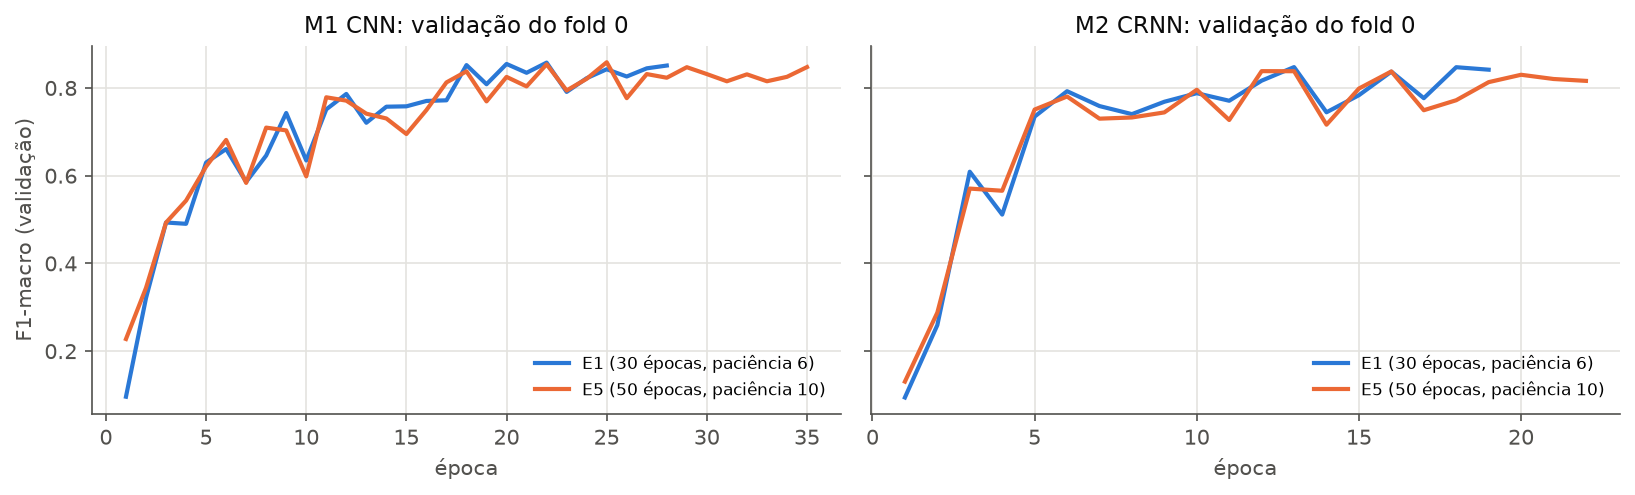

,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,veredito,obs
21,treino longo M1,0.858,0.859,8.000e-04,0.879,0.875,mantém,melhor época 25 de 35 (E1: 22 de 28)
22,treino longo M2,0.848,0.838,-9.300e-03,0.869,NaN,descarta,melhor época 12 de 22 (E1: 13 de 19)


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, m in zip(axs, ("M1", "M2")):
    nome = f"{m}_todas_e50_s42_f0"
    if not (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
        print(f"(sem {nome})"); continue
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    ck0 = torch.load(PASTA_CHECKPOINTS / f"{mh.nome_e1(m)}.pt", map_location="cpu", weights_only=False)
    h, h0 = pd.DataFrame(ck["historico"]), pd.DataFrame(ck0["historico"])
    ax.plot(h0["epoca"], h0["f1_macro"], color=graficos.SERIES[0], lw=2, label="E1 (30 épocas, paciência 6)")
    ax.plot(h["epoca"], h["f1_macro"], color=graficos.SERIES[1], lw=2, label="E5 (50 épocas, paciência 10)")
    ax.set_title(f"{graficos.NOMES_MODELOS[m]}: validação do fold 0"); ax.set_xlabel("época"); ax.legend(frameon=False, fontsize=8)
    v0, v1 = float(ck0["metricas_val"]["f1_macro"]), float(ck["metricas_val"]["f1_macro"])
    mantem = v1 > v0
    teste = None
    if mantem:
        pte, yte = mh.probs_teste(m, nome); teste = mh.f1(yte, pte)
    mh.registrar(tecnica=f"treino longo {m}", modelo=m, o_que_mudou=mh.VARIANTES[nome][2], base=f"{m} E1 (fold 0)",
                 val_f1_base=v0, val_f1=v1, teste_f1_base=float(e1.loc[m, "teste_f1_macro"]), teste_f1=teste,
                 minutos=ck["segundos"] / 60, veredito="mantém" if mantem else "descarta",
                 obs=f"melhor época {int(ck['metricas_val']['epoca'])} de {len(h)} (E1: {int(ck0['metricas_val']['epoca'])} de {len(h0)})")
axs[0].set_ylabel("F1-macro (validação)")
fig.tight_layout(); fig.savefig(FIG / "e5_treino_longo.png", bbox_inches="tight", dpi=150); plt.show()
display(mh.tabela().query("tecnica.str.startswith('treino longo')", engine="python")[["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "veredito", "obs"]].round(4))

> **Leitura.**
>
> - **Treinar mais não ajudou.** O M1 com 50 épocas para na época 35 (melhor na 25) e empata na validação (0,859 contra 0,858); no teste fica um pouco abaixo (0,875 contra 0,879). O M2 piora na validação (0,838 contra 0,848) e para cedo de novo (melhor época 12).
> - A observação da Parte 1 ("o M1 ainda melhorava na época 30") **não se confirma** com mais épocas: a curva já estava no platô, e as oscilações de ±1 ponto entre épocas vêm do aumento de dados agressivo.
> - Para o M2, o problema não é falta de épocas, e sim instabilidade da GRU com estes hiperparâmetros.

## 5.3 Divisão por gravador: quanto do desempenho é vazamento?

**O que:** refaz a divisão com `StratifiedGroupKFold` agrupando por **autor** da gravação: o teste (≈ 20%) e cada fold passam a ter gravadores que não aparecem em nenhuma outra partição. As janelas e o pré-processamento são os mesmos; só muda quem é treino, validação e teste. Treina o M1 e o M3 (fold 0, mesma configuração do E1).
**Por que:** na divisão original, ~90% das gravações de teste têm o autor também no treino. Um mesmo autor costuma gravar a mesma espécie no mesmo lugar e com o mesmo equipamento; o modelo pode aprender o "som do gravador". Esta seção não é uma técnica para melhorar o F1, é uma **medição de robustez**: se o F1 cair muito, o número do E1 é otimista.
**Como ler:** compare, para cada modelo, validação e teste na divisão original (E1) e na divisão por autor. Atenção: o teste também muda (são outras 612 gravações), então a comparação mistura "sem vazamento" com "teste diferente"; a análise da seção 8.3 do notebook 04 (mesmo teste, separado por autor visto/não visto) complementa esta.

In [7]:
j_autor = mh.janelas_por_autor()
display(mh.resumo_divisao_autor(j_autor).T.rename(columns={0: "divisão por autor"}))
for m in ("M1", "M3"):
    nome = f"{m}_todas_autor_s42_f0"
    if not (PASTA_CHECKPOINTS / nome).with_suffix(".pt").exists():
        print(f"(sem {nome})"); continue
    r = carregar_checkpoint(PASTA_CHECKPOINTS / f"{nome}.pt", m)
    m_te, _, _ = mh.avaliar_teste_janelas(r, m, mh.janelas_por_autor_para(m))
    mh.registrar(tecnica=f"divisão por autor {m}", modelo=m, o_que_mudou="StratifiedGroupKFold por autor (teste e folds sem gravadores em comum)",
                 base=f"{m} E1 (divisão por gravação, fold 0)", val_f1_base=float(e1.loc[m, "val_f1_macro"]), val_f1=float(r.metricas_val["f1_macro"]),
                 teste_f1_base=float(e1.loc[m, "teste_f1_macro"]), teste_f1=m_te["f1_macro"], minutos=r.segundos / 60,
                 veredito="medição (robustez)", obs="teste próprio (612 gravações de 96 autores fora do treino)")
display(mh.tabela().query("tecnica.str.startswith('divisão')", engine="python")[["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "obs"]].round(4))

,divisão por autor
gravacoes_teste,612
gravacoes_treino,2388
autores_teste,96
autores_treino,379
autores_em_comum,0
especies_no_teste,20
min_gravacoes_teste_por_especie,29


(sem M3_todas_autor_s42_f0)


,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,obs
10,divisão por autor M3,NaN,NaN,NaN,NaN,NaN,cortado: ~50 min de GPU por treino do M3; prio...
22,divisão por autor M1,0.858,0.814,-0.044,0.879,0.842,teste próprio (612 gravações de 96 autores for...


> **Leitura.**
>
> - A nova divisão tem **612 gravações de teste de 96 autores, nenhum em comum com o treino** (379 autores), e todas as 20 espécies no teste (mínimo de 29 gravações por espécie).
> - **O M1 cai de 0,879 para 0,842 no teste (−3,7 pontos) e de 0,858 para 0,814 na validação.** Parte do desempenho do E1 vem de reconhecer o gravador (equipamento, ambiente, indivíduos da mesma população), não só a espécie.
> - Ressalva: o teste também mudou (outras gravações), então parte da diferença pode ser dificuldade do novo teste. Ainda assim, a queda na validação aponta na mesma direção.
> - O efeito é **menor que as diferenças entre modelos** (M3 − M1 ≈ 6 pontos), então as conclusões do E1 se mantêm. Mas um número "de campo" deveria usar esta divisão.
> - Não deu para medir o M3 nesta divisão (registrado como "não executado"). Pela análise da seção 8.3 do notebook 04, não há sinal de que ele dependa mais do gravador que o M1.

## 5.4 Ajuste fino do M3 em duas fases

**O que:** nas 2 primeiras épocas só a camada nova (a saída de 20 espécies) treina, com o corpo pré-treinado congelado; depois, o modelo todo, como no E1. O resto é igual ao E1 (lr do corpo 1e-4, cabeça 1e-3, aumento "todas").
**Por que:** no início do ajuste fino a camada nova é aleatória e seus gradientes grandes atravessam o corpo pré-treinado, podendo apagar parte do que veio do AudioSet. Congelar o corpo até a cabeça "assentar" é a receita padrão para evitar isso. É a única variante do M3 mantida, por ser a única técnica específica de modelos pré-treinados (as outras foram para o M1, na seção 5.8).
**Como ler:** compare com o M3 do E1 na validação; só vai ao teste se superar.

In [8]:
var_m3 = [n for n in mh.VARIANTES if n.startswith("M3_")]
v0 = float(e1.loc["M3", "val_f1_macro"])
res_m3 = []
for nome in var_m3:
    if not (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
        print(f"(sem {nome})"); continue
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    res_m3.append((nome, float(ck["metricas_val"]["f1_macro"]), ck["segundos"] / 60, int(ck["metricas_val"]["epoca"]), len(ck["historico"]["epoca"])))
escolhida = max(res_m3, key=lambda t: t[1]) if res_m3 else None
for nome, v, minutos, ep, n_ep in res_m3:
    mantem = nome == escolhida[0] and v > v0
    teste = None
    if mantem:
        pte, yte = mh.probs_teste("M3", nome); teste = mh.f1(yte, pte)
    mh.registrar(tecnica={"M3_todas_2fases_s42_f0": "M3 duas fases"}.get(nome, nome), modelo="M3", o_que_mudou=mh.VARIANTES[nome][2],
                 base="M3 E1 (fold 0)", val_f1_base=v0, val_f1=v, teste_f1_base=float(e1.loc["M3", "teste_f1_macro"]), teste_f1=teste,
                 minutos=minutos, veredito="mantém" if mantem else "descarta", obs=f"melhor época {ep} de {n_ep}")
display(mh.tabela().query("modelo == 'M3' and not tecnica.str.startswith('divisão') and not tecnica.str.startswith('TTA')", engine="python")
        [["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "minutos", "veredito"]].round(4))

(sem M3_todas_ls01_s42_f0)
(sem M3_todas_lrb3e-5_s42_f0)
(sem M3_todas_lrb3e-4_s42_f0)


,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,minutos,veredito
6,"M3 label smoothing 0,1",NaN,NaN,NaN,NaN,NaN,NaN,não executado
7,M3 lr do corpo 3e-5,NaN,NaN,NaN,NaN,NaN,NaN,não executado
8,M3 lr do corpo 3e-4,NaN,NaN,NaN,NaN,NaN,NaN,não executado
18,agregação M3,0.923,0.936,0.012,0.939,0.932,0.000,mantém
22,M3 duas fases,0.923,0.869,-0.054,0.939,NaN,32.261,descarta


> **Leitura.**
>
> - **As duas fases pioraram o M3 bastante:** validação 0,869 contra 0,923 do E1 (−5,4 pontos), com parada antecipada na época 11 (melhor na 7). Descartada.
> - Uma explicação plausível está no histórico de treino:
>   - nas 2 épocas com o corpo congelado, a cabeça treinou sobre características fixas com aumento de dados forte e chegou a só 0,48;
>   - essas épocas consumiram parte da agenda cosseno de 15 épocas, então o corpo foi ajustado com taxas já menores e por menos tempo;
>   - com paciência 4, um platô curto encerrou o treino cedo.
> - Ou seja, no M3 os gradientes da cabeça aleatória não atrapalham: o ajuste fino direto do E1, com taxa 10 vezes menor no corpo, já protege o pré-treino.
> - Ressalva: um único treino. Com mais épocas ou paciência, a diferença provavelmente diminuiria.

## 5.5 M5: CNN de imagem pré-treinada no ImageNet sobre o log-Mel

**O que:** EfficientNet-B0 (4 milhões de parâmetros, pesos do ImageNet via `timm`) recebendo o mesmo log-Mel 128 × 313 do M1, com o mesmo aumento e o mesmo protocolo (fold 0). A primeira convolução é adaptada de 3 canais (RGB) para 1 somando os pesos. Taxa 3e-4 no corpo e 1e-3 na cabeça, até 30 épocas.
**Por que:** separa duas explicações para a vantagem do M3: "qualquer pré-treino ajuda" ou "pré-treino *em áudio* ajuda". Um espectrograma não é uma foto, mas bordas e texturas aprendidas no ImageNet costumam transferir.
**Como ler:** compare o M5 com o M1 (mesma entrada, do zero) e com o M3 (pré-treinado em áudio). Como o M5 é um modelo novo de comparação (não uma escolha de hiperparâmetro), ele vai ao teste uma vez.

In [9]:
nome = "M5_todas_s42_f0"
if (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    p5, y5 = mh.probs_teste("M5", nome)
    v5, t5 = float(ck["metricas_val"]["f1_macro"]), mh.f1(y5, p5)
    mh.registrar(tecnica="M5 EfficientNet-B0 (ImageNet)", modelo="M5", o_que_mudou=mh.VARIANTES[nome][2],
                 base="M1 E1 (fold 0), mesma entrada", val_f1_base=float(e1.loc["M1", "val_f1_macro"]), val_f1=v5,
                 teste_f1_base=float(e1.loc["M1", "teste_f1_macro"]), teste_f1=t5, minutos=ck["segundos"] / 60,
                 veredito="comparação", obs=f"M3 (AudioSet): val {e1.loc['M3', 'val_f1_macro']:.3f}, teste {e1.loc['M3', 'teste_f1_macro']:.3f}")
    comp = pd.DataFrame({"modelo": ["M1 (do zero)", "M5 (ImageNet)", "M3 (AudioSet)"],
                         "parâmetros (milhões)": [0.39, 4.0, 79.7],
                         "F1 val. (fold 0)": [e1.loc["M1", "val_f1_macro"], v5, e1.loc["M3", "val_f1_macro"]],
                         "F1 teste": [e1.loc["M1", "teste_f1_macro"], t5, e1.loc["M3", "teste_f1_macro"]],
                         "min de treino": [e1.loc["M1", "minutos"], ck["segundos"] / 60, e1.loc["M3", "minutos"]]}).set_index("modelo")
    display(comp.round(3))

,parâmetros (milhões),F1 val. (fold 0),F1 teste,min de treino
modelo,,,,
M1 (do zero),0.39,0.858,0.879,9.978
M5 (ImageNet),4.00,0.904,0.923,23.766
M3 (AudioSet),79.70,0.923,0.939,50.061


> **Leitura.**
>
> - **O pré-treino em imagens também ajuda muito.** O M5 (EfficientNet-B0 do ImageNet) chega a 0,923 no teste: **+4,4 pontos sobre o M1**, com a mesma entrada e o mesmo aumento.
> - **O pré-treino em áudio ajuda mais:** o M3 fica 1,6 ponto acima (0,939), com 20 vezes mais parâmetros (80 milhões contra 4) e o dobro do tempo de treino.
> - As duas explicações do "por que o M3 vence" valem em parte: filtros genéricos de bordas e texturas já trazem a maior parte do ganho, e o pré-treino no domínio certo acrescenta o resto.
> - **Custo-benefício:** o M5 é o modelo mais equilibrado do projeto, quase o desempenho do M3 com 1/20 dos parâmetros (~16 MB), treinando em 24 min numa GPU de 4 GB.

## 5.6 Ajuste fino parcial do AST

**O que:** o M4 usa o AST inteiro congelado e treina só uma camada linear. Aqui os **2 últimos blocos** do *transformer* (de 12) e o LayerNorm final também treinam (14 milhões de parâmetros treináveis, contra 15 mil no M4), com taxa 3e-5 nesses blocos e 1e-3 na cabeça, lote 8, até 6 épocas. A entrada é o fbank do próprio extrator do AST nas mesmas janelas; continua sem aumento de dados, para mudar uma coisa só em relação ao M4.
**Por que:** no E1 o M4 ficou abaixo até do M1. Uma explicação é que o embedding do AST, treinado para as 527 classes genéricas do AudioSet, não separa bem espécies de aves *sem adaptação*; outra é que o AST simplesmente não serve para este problema. Adaptar os últimos blocos distingue as duas. Os blocos congelados não guardam ativações para o *backward*, o que faz caber em 4 GB.
**Como ler:** compare com o M4 (mesma entrada e mesmo AST, só a cabeça treinada). Por ser uma variante de modelo de comparação, vai ao teste uma vez.

,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,minutos,veredito
22,AST ajuste fino parcial,0.839,0.848,0.009,0.823,0.853,146.459,mantém


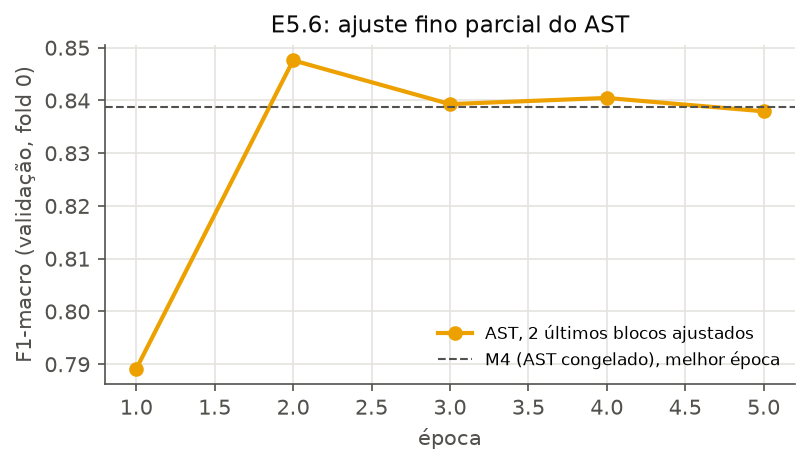

In [10]:
nome = "M4FT_sem_s42_f0"
if (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    p6, y6 = mh.probs_teste("M4FT", nome)
    v6, t6 = float(ck["metricas_val"]["f1_macro"]), mh.f1(y6, p6)
    mh.registrar(tecnica="AST ajuste fino parcial", modelo="M4FT", o_que_mudou=mh.VARIANTES[nome][2],
                 base="M4 E1 (fold 0), AST congelado", val_f1_base=float(e1.loc["M4", "val_f1_macro"]), val_f1=v6,
                 teste_f1_base=float(e1.loc["M4", "teste_f1_macro"]), teste_f1=t6, minutos=ck["segundos"] / 60,
                 veredito="mantém" if v6 > float(e1.loc["M4", "val_f1_macro"]) else "descarta",
                 obs=f"melhor época {int(ck['metricas_val']['epoca'])} de {len(ck['historico']['epoca'])}")
    display(mh.tabela().query("modelo == 'M4FT'")[["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "minutos", "veredito"]].round(4))
    h = pd.DataFrame(ck["historico"])
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    ax.plot(h["epoca"], h["f1_macro"], marker="o", color=graficos.SERIES[3], lw=2, label="AST, 2 últimos blocos ajustados")
    ax.axhline(float(e1.loc["M4", "val_f1_macro"]), color=graficos.TEXTO_2, ls="--", lw=1, label="M4 (AST congelado), melhor época")
    ax.set_xlabel("época"); ax.set_ylabel("F1-macro (validação, fold 0)"); ax.legend(frameon=False, fontsize=8)
    ax.set_title("E5.6: ajuste fino parcial do AST"); fig.tight_layout(); fig.savefig(FIG / "e5_ast_parcial.png", dpi=150); plt.show()
else:
    print("(checkpoint M4FT ainda não treinado)")

> **Leitura.**
>
> - **Adaptar os 2 últimos blocos do AST ajuda:** o teste vai de 0,823 (M4, só a cabeça) para **0,853** (+3,0 pontos), e a validação de 0,839 para 0,848. O AST não é inútil para o problema: o embedding genérico é que precisa de adaptação.
> - Mesmo assim, ele fica **bem abaixo do M3** (0,939) e do M5 (0,923):
>   - o melhor ponto é a época 2;
>   - depois a perda de treino cai para quase zero (0,035 na época 5) sem melhora na validação, um sobreajuste rápido, esperado com 14 milhões de parâmetros livres e **sem aumento de dados**.
> - **Custo:** 146 min (~27 min por época). O fbank completo não cabe na VRAM e é lido do disco; cada janela passa pelos 12 blocos do *transformer*. Foi o treino mais caro do E5 para um ganho modesto.
> - O próximo passo natural (aumento de dados no fbank, mais blocos ajustados) exige uma GPU maior.

## 5.7 Calibração: as probabilidades são confiáveis?

**O que:** *temperature scaling*. As probabilidades de cada gravação são reescaladas por uma temperatura T (p ∝ p^(1/T)); T > 1 suaviza, T < 1 aguça. T é escolhido minimizando a log-verossimilhança negativa (NLL) **na validação**; como só reescala, **não muda a espécie prevista nem o F1**. Medimos o ECE (*expected calibration error*: diferença média entre confiança e acurácia, em 15 faixas) e desenhamos a curva de confiabilidade.
**Por que:** na inferência (`birdclef.inferencia`) mostramos "espécie X com 87%". Esse número só é útil se, entre as previsões com ~87% de confiança, ~87% estiverem certas. A média de janelas e o mixup tendem a deixar o modelo pouco confiante; o *label smoothing* também.
**Modelo:** o **ensemble final** (média ponderada M1+M2+M3, seção 5.1), que é o padrão da inferência.
**Como ler:** ECE menor = melhor; na figura, quanto mais perto da diagonal, mais calibrado. O critério para manter a temperatura é o ECE de validação; o de teste é reportado.

ECE    NLL  confiança média  acurácia
conjunto  versão                                           
validação original  0.230  0.543            0.699     0.929
          T = 0.53  0.038  0.349            0.904     0.929
teste     original  0.230  0.467            0.713     0.943
          T = 0.53  0.027  0.247            0.916     0.943

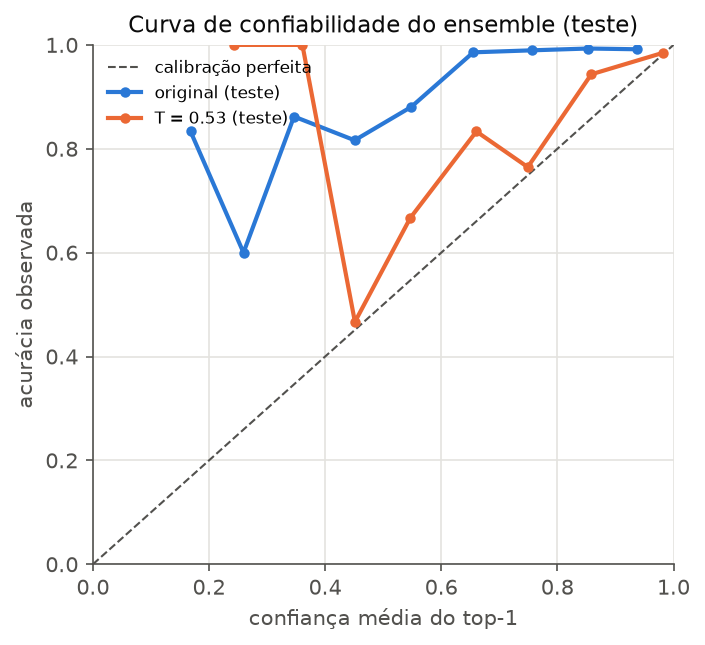

In [11]:
membros = list(ens["pesos"])
Pv = np.tensordot(np.array([ens["pesos"][m] for m in membros]), np.stack([mh.probs_val(m, mh.nome_e1(m))[0] for m in membros]), 1)
yv = mh.probs_val("M1", mh.nome_e1("M1"))[1]
Pt = np.tensordot(np.array([ens["pesos"][m] for m in membros]), np.stack([mh.probs_teste(m, mh.nome_e1(m))[0] for m in membros]), 1)
T = mh.ajustar_temperatura(yv, Pv)
cal = pd.DataFrame([{"conjunto": c, "versão": v, "ECE": mh.ece(y, p), "NLL": mh.nll(y, p), "confiança média": p.max(1).mean(),
                     "acurácia": (p.argmax(1) == y).mean()}
                    for c, y, P in (("validação", yv, Pv), ("teste", y_te, Pt))
                    for v, p in (("original", P), (f"T = {T:.2f}", mh.com_temperatura(P, T)))]).set_index(["conjunto", "versão"])
display(cal.round(4))
ece_v0, ece_v1 = cal.loc[("validação", "original"), "ECE"], cal.loc[("validação", f"T = {T:.2f}"), "ECE"]
mantem = ece_v1 < ece_v0
mh.registrar(tecnica="calibração (temperature scaling)", modelo="ensemble M1+M2+M3",
             o_que_mudou=f"probabilidades reescaladas com T = {T:.2f} (ajustado na validação); F1 não muda",
             base="ensemble sem temperatura", val_f1_base=None, val_f1=None, teste_f1_base=None, teste_f1=None, minutos=0.0,
             veredito="mantém" if mantem else "descarta",
             obs=f"ECE val {ece_v0:.3f} → {ece_v1:.3f}; ECE teste {cal.loc[('teste', 'original'), 'ECE']:.3f} → {cal.loc[('teste', f'T = {T:.2f}'), 'ECE']:.3f}")
graficos.confiabilidade({"original (teste)": mh.curva_confiabilidade(y_te, Pt),
                         f"T = {T:.2f} (teste)": mh.curva_confiabilidade(y_te, mh.com_temperatura(Pt, T))},
                        FIG / "e5_confiabilidade.png", "Curva de confiabilidade do ensemble (teste)")
display(Image(FIG / "e5_confiabilidade.png"))

> **Leitura.**
>
> - **O ensemble é pouco confiante, não excessivamente confiante.** A confiança média é 0,71, mas a acurácia é 0,94: quando diz "70%", acerta muito mais do que isso. É o efeito esperado de três médias (das janelas, dos modelos e o mixup, que treina com alvos misturados).
> - **A temperatura T = 0,53 (< 1, aguça as probabilidades) corrige quase tudo:** o ECE do teste cai de 0,230 para **0,027** e a NLL de 0,467 para 0,247. A temperatura foi escolhida na validação e o teste melhora tanto quanto ela: a correção generaliza.
> - Na curva, a versão original fica toda acima da diagonal (pouco confiante). A calibrada se aproxima dela, sobretudo na faixa de alta confiança, onde está a maioria das gravações. Os pontos de confiança abaixo de 0,5 têm poucas gravações e oscilam muito.
> - **Mantida:** o ensemble final (`checkpoints/finais/ensemble.json`) guarda a sua temperatura, ajustada da mesma forma (T = 0,46), e a inferência a aplica. A porcentagem mostrada ao usuário passa a significar chance de acerto.

## 5.8 Técnicas no M1: *label smoothing*, destilação do M3 e PCEN

**O que:** três técnicas de famílias diferentes, cada uma mudando **uma** coisa no M1 do E1 (fold 0, mesmo aumento, mesmos hiperparâmetros):

| técnica | família | o que muda |
|---|---|---|
| *label smoothing* 0,1 | regularização | alvo 0,9 na espécie correta e 0,1/20 nas outras |
| destilação do M3 | transferência de conhecimento | alvo = 0,5·rótulo + 0,5·probabilidades do M3 do fold 0 na mesma janela (temperatura 2) |
| PCEN | representação da entrada (processamento de sinais) | a CNN vê a PCEN (normalização de energia por canal, com constante de tempo de 0,4 s) em vez do log-Mel |

**Por que:**
- ***Label smoothing***: o rótulo é fraco (nem toda janela de 5 s contém o canto) e o modelo tende a ficar confiante demais.
- **Destilação**: o M3 é ~6 pontos melhor, mas tem 200 vezes mais parâmetros. As probabilidades dele carregam informação que o rótulo não tem ("esta janela parece 70% bem-te-vi, 20% suiriri"); a pergunta é quanto desse ganho cabe numa CNN de 0,4 milhão de parâmetros, que roda em qualquer lugar.
- **PCEN**: técnica clássica de bioacústica que normaliza cada banda pela própria energia recente; realça eventos curtos (cantos) e atenua ruído de fundo estacionário (chuva, vento, insetos), exatamente o tipo de ruído do E3. O ruído, o SpecAugment e o mixup continuam agindo como no M1, antes da PCEN.

**Professor sem vazamento:** o M3 do fold 0 foi treinado nas mesmas janelas de treino do fold 0; a validação e o teste não entram na destilação.
**Como ler:** cada técnica contra o M1 do E1 na validação; as que melhorarem vão ao teste. Para a PCEN também medimos o teste com ruído (é a pergunta natural sobre ela), mas só se ela for mantida.

In [12]:
v0 = float(e1.loc["M1", "val_f1_macro"])
for nome, tecnica in [("M1_todas_ls01_s42_f0", "label smoothing M1"), ("M1_todas_destil_s42_f0", "destilação M3 → M1"),
                      ("M1PCEN_todas_s42_f0", "PCEN M1")]:
    if not (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
        print(f"(sem {nome})"); continue
    arq_mod = mh.VARIANTES[nome][0]
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    v = float(ck["metricas_val"]["f1_macro"])
    mantem = v > v0
    teste, obs = None, f"melhor época {int(ck['metricas_val']['epoca'])} de {len(ck['historico']['epoca'])}"
    if mantem:
        pte, yte = mh.probs_teste(arq_mod, nome); teste = mh.f1(yte, pte)
        if arq_mod == "M1PCEN":
            versoes, jan_te = e.versoes_teste("M1")
            r = carregar_checkpoint(PASTA_CHECKPOINTS / f"{nome}.pt", "M1PCEN")
            f0 = treino.avaliar_teste(r, versoes["0 dB"], jan_te)[0]["f1_macro"]
            e3b_m1 = pd.read_csv("resultados/e3b/e3b_execucoes.csv").query("modelo == 'M1' and aumento == 'todas'").set_index("teste")["f1_macro"]
            obs += f"; teste a 0 dB: {f0:.3f} (M1 log-Mel: {e3b_m1['0 dB']:.3f})"
    mh.registrar(tecnica=tecnica, modelo=arq_mod, o_que_mudou=mh.VARIANTES[nome][2], base="M1 E1 (fold 0)",
                 val_f1_base=v0, val_f1=v, teste_f1_base=float(e1.loc["M1", "teste_f1_macro"]), teste_f1=teste,
                 minutos=ck["segundos"] / 60, veredito="mantém" if mantem else "descarta", obs=obs)
display(mh.tabela().query("tecnica in ['label smoothing M1', 'destilação M3 → M1', 'PCEN M1']")
        [["tecnica", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "minutos", "veredito", "obs"]].round(4))

,tecnica,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,minutos,veredito,obs
20,label smoothing M1,0.858,0.866,0.008,0.879,0.868,11.932,mantém,melhor época 20 de 26
21,destilação M3 → M1,0.858,0.853,-0.005,0.879,NaN,13.929,descarta,melhor época 25 de 30
22,PCEN M1,0.858,0.869,0.011,0.879,0.902,15.272,mantém,melhor época 29 de 30; teste a 0 dB: 0.875 (M1...


> **Leitura.**
>
> - ***Label smoothing:*** melhora a validação (+0,008), mas **piora o teste** (0,868 contra 0,879). É mais um ganho de validação dentro do ruído que não se sustenta. Com mixup, os alvos já são suaves, e a suavização extra sobra.
> - **Destilação do M3:** piora levemente a validação (0,853 contra 0,858) e foi descartada. Com mixup e rótulos já misturados, as probabilidades do professor (que acerta ~93% e por isso fica perto do rótulo) acrescentam pouca informação, e uma CNN de 0,4 milhão de parâmetros talvez não tenha capacidade para imitar o M3. Outras temperaturas e pesos ficam como trabalho futuro.
> - **PCEN: a melhoria mais clara do E5.**
>   - validação 0,869 (+0,011) e **teste 0,902 (+2,3 pontos sobre o M1 com log-Mel)**;
>   - **a 0 dB, 0,875 contra 0,849** (+2,6 pontos);
>   - a melhor época foi a 29 de 30, então ainda havia margem com mais épocas.
>
>   A PCEN faz o que se espera dela: normaliza cada banda pela energia recente, realça os eventos curtos (notas) e achata o ruído de fundo estacionário (chuva, vento, insetos). É uma técnica clássica de processamento de sinais que, dentro da rede, vale mais que trocar o classificador (seção 5.0).

## 5.9 M6: a CNN do projeto

**O que:** uma CNN nossa, do mesmo porte do M1 (~0,3 milhão de parâmetros), montada com estruturas conhecidas. **Cada peça foi escolhida por causa de um resultado deste trabalho:**

| peça | estrutura conhecida | motivo (resultado nosso) |
|---|---|---|
| 1. PCEN treinável | PCEN com os parâmetros aprendidos por banda Mel (Wang et al., 2017; LEAF, Zeghidour et al., 2021) | a PCEN fixa foi a melhor técnica da seção 5.8 (+2,3 pontos no teste, +2,6 a 0 dB); deixar cada banda aprender sua constante de tempo e compressão é o passo natural |
| 2. blocos residuais com SE | ResNet (He et al., 2016) + *Squeeze-and-Excitation* (Hu et al., 2018) | o M1 tem 4 blocos simples; atalhos residuais e atenção entre canais são o padrão das soluções vencedoras do BirdCLEF |
| 3. posição na frequência | canal de coordenada da banda, como no CoordConv (Liu et al., 2018) | cada espécie canta numa faixa própria (Grad-CAM, confusão Saltator × Wood-Wren no notebook 04); uma CNN comum é invariante à posição e não "sabe" em que frequência está o traço |
| 4. atenção nas janelas | *multiple-instance learning* com atenção com portas (Ilse et al., 2018) | o rótulo é da gravação (rótulo fraco; núcleo de janelas sem canto no t-SNE); as regras fixas de agregação (máximo, top-3) não melhoraram o teste na seção 5.1 |

**Como foi testado (ablação, uma peça por vez):** fold 0, mesmo aumento e mesmos hiperparâmetros do M1 (30 épocas, paciência 6, lr 1e-3).

| variante | o que acrescenta | comparada com |
|---|---|---|
| M6a | PCEN treinável na CNN do M1 | M1 com PCEN fixa (5.8) |
| M6b | + blocos residuais com SE (larguras 16-32-64-128, para manter o porte do M1) | M6a |
| M6c | + canal de frequência | M6b |
| **M6** | + atenção nas janelas (2ª etapa: corpo congelado, só a atenção treina), sobre a melhor base até aqui | a base |

**Por que a atenção numa 2ª etapa:** as três primeiras variantes treinam janela a janela, como todos os modelos. A atenção precisa da gravação inteira; treiná-la com o corpo congelado faz com que a única diferença em relação à base seja *como* as janelas viram a predição: média das probabilidades ou média ponderada por uma atenção aprendida. Como uma peça só fica se melhorar a validação, a atenção é aplicada sobre a melhor base até aqui (se o canal de frequência piorar, sobre o M6b).

**Como ler:** cada passo é mantido se melhorar a validação em relação ao anterior. O M6 final, como modelo de comparação (igual ao M5), vai ao teste uma vez, também a 0 dB.

,parâmetros,F1 val. (fold 0),min de treino,dif. para o passo anterior
variante,,,,
M1 (E1),393460,0.858,9.978,NaN
M1 + PCEN fixa (5.8),393462,0.869,15.272,0.011
M6a: PCEN treinável,393974,0.879,13.527,0.010
M6b: + residual SE,319234,0.931,21.141,0.052
M6c: + frequência,319394,0.914,21.435,-0.017
M6c + atenção,335971,0.912,0.603,-0.002
M6: M6b + atenção (final),335811,0.932,0.909,0.019


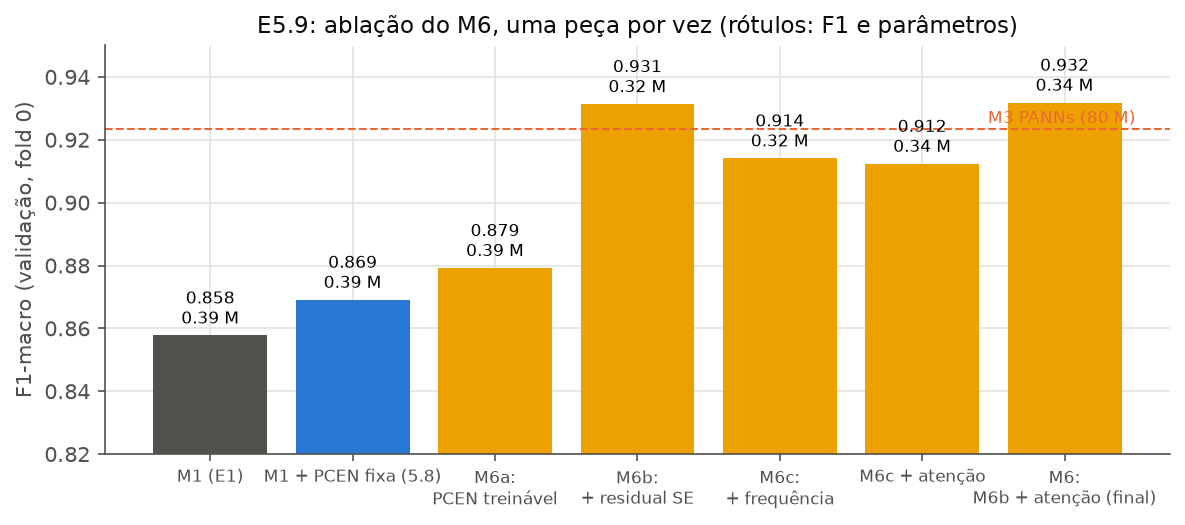

In [13]:
from birdclef import m6 as m6mod
passos = [("M1 (E1)", "M1", mh.nome_e1("M1"), None),
          ("M1 + PCEN fixa (5.8)", "M1PCEN", "M1PCEN_todas_s42_f0", None),
          ("M6a: PCEN treinável", "M6a", "M6a_todas_s42_f0", "PCEN M1"),
          ("M6b: + residual SE", "M6b", "M6b_todas_s42_f0", "M6a: PCEN treinável"),
          ("M6c: + frequência", "M6c", "M6c_todas_s42_f0", "M6b: + residual SE"),
          ("M6c + atenção", "M6", "M6_todas_s42_f0", "M6c: + frequência"),
          ("M6: M6b + atenção (final)", "M6bA", "M6bA_todas_s42_f0", "M6b: + residual SE")]
linhas_m6, val_de = [], {}
for rotulo, arq_mod, nome, anterior in passos:
    if not (PASTA_CHECKPOINTS / f"{nome}.pt").exists():
        print(f"(sem {nome})"); continue
    ck = torch.load(PASTA_CHECKPOINTS / f"{nome}.pt", map_location="cpu", weights_only=False)
    v = float(ck["metricas_val"]["f1_macro"]); val_de[rotulo] = v
    rede = __import__("birdclef.modelos", fromlist=["criar"]).criar(arq_mod, 20, pretreinado=False)
    linhas_m6.append({"variante": rotulo, "parâmetros": sum(p.numel() for p in rede.parameters() if p.requires_grad),
                      "F1 val. (fold 0)": v, "min de treino": ck["segundos"] / 60})
tab_m6 = pd.DataFrame(linhas_m6).set_index("variante")
tab_m6["dif. para o passo anterior"] = tab_m6["F1 val. (fold 0)"].diff()
display(tab_m6.round(4))

# registro: cada peça contra o passo anterior; teste só para as mantidas
for rotulo, arq_mod, nome, anterior in passos[2:]:
    if rotulo not in val_de or anterior not in val_de and anterior != "PCEN M1":
        continue
    v_ant = val_de["M1 + PCEN fixa (5.8)"] if anterior == "PCEN M1" else val_de[anterior]
    mantem = val_de[rotulo] > v_ant
    teste = mh.f1(*reversed(mh.probs_teste(arq_mod, nome))) if mantem else None
    mh.registrar(tecnica=f"M6 ablação: {rotulo}", modelo=arq_mod, o_que_mudou=mh.VARIANTES[nome][2] if nome in mh.VARIANTES
                 else "atenção com portas sobre os embeddings das janelas da gravação (corpo e saída do M6c congelados)",
                 base=anterior if anterior != "PCEN M1" else "M1 + PCEN fixa (5.8)", val_f1_base=v_ant, val_f1=val_de[rotulo],
                 teste_f1_base=None, teste_f1=teste,
                 minutos=float(tab_m6.loc[rotulo, "min de treino"]), veredito="mantém" if mantem else "descarta",
                 obs=f"{int(tab_m6.loc[rotulo, 'parâmetros']):,} parâmetros".replace(",", "."))

fig, ax = plt.subplots(figsize=(8, 3.6))
cores = [graficos.TEXTO_2, graficos.SERIES[0]] + [graficos.SERIES[3]] * (len(tab_m6) - 2)
ax.bar(range(len(tab_m6)), tab_m6["F1 val. (fold 0)"], color=cores[:len(tab_m6)])
for i, (v, n) in enumerate(zip(tab_m6["F1 val. (fold 0)"], tab_m6["parâmetros"])):
    ax.text(i, v + 0.002, f"{v:.3f}\n{n / 1e6:.2f} M", ha="center", va="bottom", fontsize=8)
ax.axhline(float(e1.loc["M3", "val_f1_macro"]), color=graficos.SERIES[1], ls="--", lw=1)
ax.text(len(tab_m6) - 0.5, float(e1.loc["M3", "val_f1_macro"]) + 0.002, "M3 PANNs (80 M)", ha="right", fontsize=8, color=graficos.SERIES[1])
ax.set_xticks(range(len(tab_m6))); ax.set_xticklabels([r.replace(": ", ":\n") for r in tab_m6.index], fontsize=8)
ax.set_ylim(0.82, 0.95); ax.set_ylabel("F1-macro (validação, fold 0)")
ax.set_title("E5.9: ablação do M6, uma peça por vez (rótulos: F1 e parâmetros)")
fig.tight_layout(); fig.savefig(FIG / "e5_m6_ablacao.png", dpi=150, bbox_inches="tight"); plt.show()

> **Leitura.** (A coluna "dif. para o passo anterior" compara cada linha com a de cima; o M6 final se compara com o M6b, sua base: +0,001.)
>
> | passo | validação | teste | veredito |
> |---|---|---|---|
> | PCEN fixa → **PCEN treinável** (M6a) | 0,869 → 0,879 | 0,902 → 0,893 | mantida pela validação |
> | + **blocos residuais com SE** (M6b) | 0,879 → **0,931** | **0,924** | o grande salto |
> | + canal de frequência (M6c) | 0,931 → 0,914 | – | descartado |
> | + atenção nas janelas (M6 final, sobre o M6b) | 0,931 → 0,932 | 0,924 → 0,914 | empate na validação, perde no teste |
>
> - **A peça que mais contribuiu foram os blocos residuais com SE: +5,2 pontos na validação, com menos parâmetros que o M1** (0,32 contra 0,39 milhão). Atalhos residuais e a recalibração de canais do SE deixam a rede mais profunda em efeito sem aumentar o porte.
> - **O M6b chega a 0,924 no teste: igual ao EfficientNet-B0 do ImageNet (0,923, 4 milhões de parâmetros, 12 vezes mais), sem nenhum pré-treino**, e a 1,5 ponto do M3 (80 milhões, 250 vezes mais).
> - **A PCEN treinável** ganhou 1 ponto na validação, mas no teste ficou 0,9 abaixo da fixa. O ganho dela, sozinha, está dentro do ruído; o que importa é que ela é a entrada da base que funcionou.
> - **O canal de frequência piorou** (−1,7). Com pooling global e 4 reduções, a rede já sabe a banda pelo padrão dos filtros, e a coordenada parece só ter facilitado o sobreajuste.
> - **A atenção nas janelas empatou na validação (+0,001) e perdeu 1 ponto no teste.** Pelo protocolo, o M6 final (escolhido na validação) é o com atenção, e o número dele no teste é **0,914**. Fica registrado que, aqui, a média simples das janelas é tão boa quanto a atenção aprendida, assim como as regras fixas de agregação na seção 5.1.
> - Ressalva: um treino por variante (fold 0, semente 42). A diferença do M6b para o M1 (+4,5 pontos no teste) é bem maior que a variação entre folds do E1 (~1 ponto); as diferenças de ~1 ponto entre passos não são.

### O que a PCEN aprendeu e para onde a atenção olha

**O que:** à esquerda, os parâmetros da PCEN treinável do M6 em cada banda Mel, comparados com a PCEN fixa (linha tracejada): a constante de tempo (em segundos; quanto do passado recente conta como "fundo") e o expoente de compressão r. À direita, uma gravação de teste: o log-Mel das janelas lado a lado e, em cima, o peso que a atenção deu a cada uma.
**Como ler:** se a PCEN aprendesse a mesma coisa em todas as bandas, as curvas seriam planas. Na atenção, um bom sinal é peso alto nas janelas com canto visível e baixo nas de silêncio ou ruído.

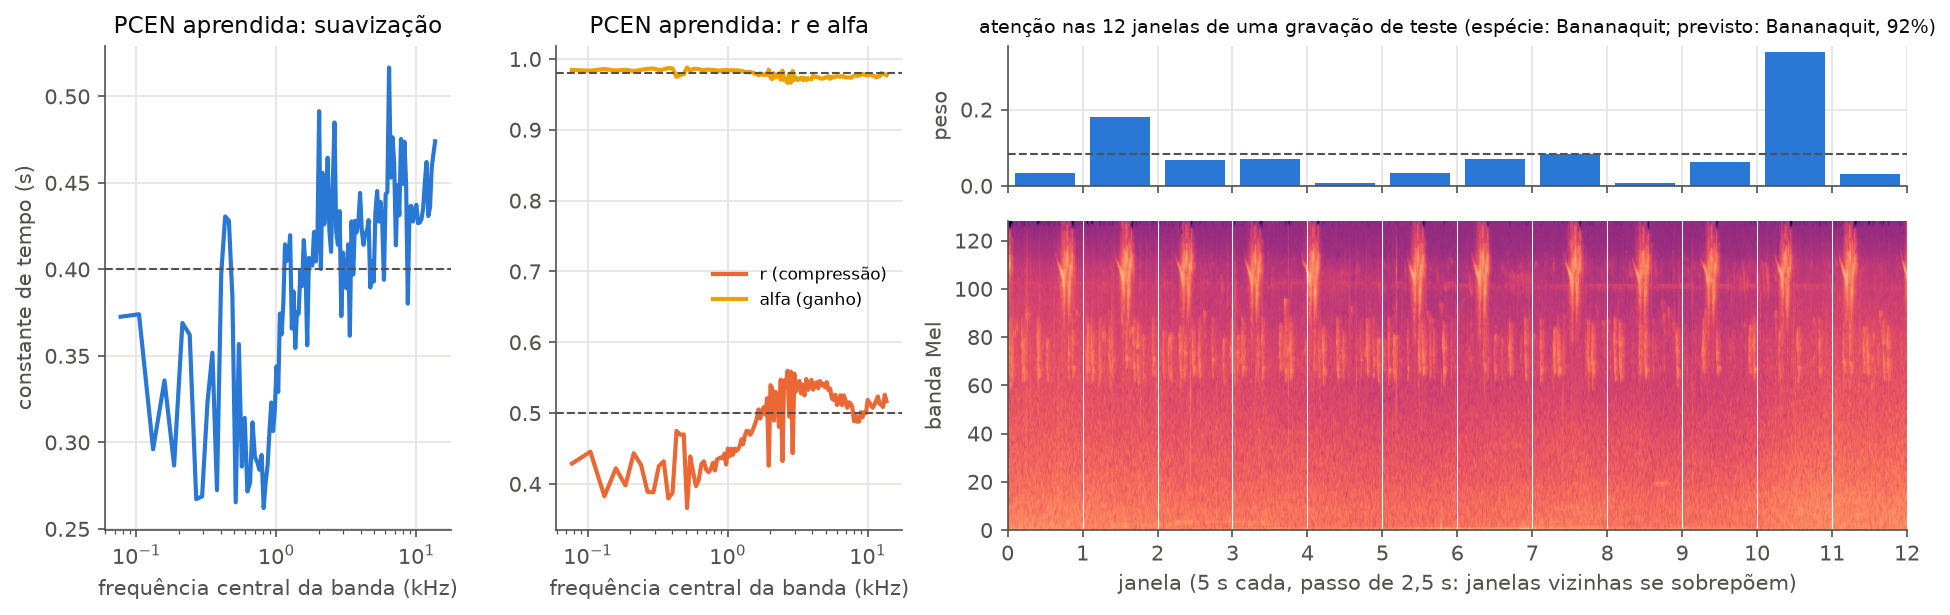

constante de tempo aprendida: de 0.26 s a 0.52 s (fixa: 0,40 s); r de 0.37 a 0.56 (fixo: 0,50); alfa de 0.97 a 0.99 (fixo: 0,98)
pesos da atenção: de 0.007 a 0.350 (uniforme: 0.083)


In [14]:
from birdclef import preproc
m6m, ck6 = m6mod.carregar("M6bA_todas_s42_f0")
v6 = {k: t.detach().cpu().numpy() for k, t in m6m.pcen.valores().items()}
tempo_s = np.sqrt(1 - v6["s"]) / v6["s"] * 512 / 32000      # constante de tempo do filtro, em segundos
f_centro = __import__("librosa").mel_frequencies(n_mels=130, fmin=preproc.MEL128_32K.fmin, fmax=preproc.MEL128_32K.fmax)[1:-1] / 1000

X6, j6, _ = e.dados_modelo("M6bA")
idx_te6 = np.flatnonzero((j6.particao == "teste").to_numpy())
arq_te = j6.filename.to_numpy()[idx_te6]
cont = pd.Series(arq_te).value_counts()
exemplo = sorted(cont[cont == 12].index)[3]                   # uma gravação de teste com 12 janelas
ix = idx_te6[arq_te == exemplo]
x = torch.from_numpy(np.asarray(X6[ix], dtype=np.float32)).to(next(m6m.parameters()).device)
with torch.no_grad():
    h = m6m.embedding((x - ck6["norm"][0]) / ck6["norm"][1]).float()[None]
    pesos = m6m.atencao.pesos(h, torch.ones(h.shape[:2], dtype=torch.bool, device=h.device))[0].cpu().numpy()
    p_grav = torch.softmax(m6m.logits_gravacao(h, torch.ones(h.shape[:2], dtype=torch.bool, device=h.device)), 1)[0].cpu().numpy()
classes6 = ck6["classes"]

fig = plt.figure(figsize=(13, 4.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 2.6], height_ratios=[1, 2.2])
ax1 = fig.add_subplot(gs[:, 0]); ax2 = fig.add_subplot(gs[:, 1])
ax1.plot(f_centro, tempo_s, color=graficos.SERIES[0], lw=2); ax1.axhline(0.4, color=graficos.TEXTO_2, ls="--", lw=1)
ax1.set_xscale("log"); ax1.set_xlabel("frequência central da banda (kHz)"); ax1.set_ylabel("constante de tempo (s)")
ax1.set_title("PCEN aprendida: suavização")
ax2.plot(f_centro, v6["r"], color=graficos.SERIES[1], lw=2, label="r (compressão)")
ax2.plot(f_centro, v6["alfa"], color=graficos.SERIES[3], lw=2, label="alfa (ganho)")
ax2.axhline(0.5, color=graficos.TEXTO_2, ls="--", lw=1); ax2.axhline(0.98, color=graficos.TEXTO_2, ls="--", lw=1)
ax2.set_xscale("log"); ax2.set_xlabel("frequência central da banda (kHz)"); ax2.set_title("PCEN aprendida: r e alfa")
ax2.legend(frameon=False, fontsize=8)
ax3 = fig.add_subplot(gs[0, 2]); ax4 = fig.add_subplot(gs[1, 2], sharex=ax3)
ax3.bar(np.arange(12) + 0.5, pesos, width=0.8, color=graficos.SERIES[0]); ax3.axhline(1 / 12, color=graficos.TEXTO_2, ls="--", lw=1)
from birdclef import dados
nome_comum = dados.carregar_metadados().drop_duplicates("primary_label").set_index("primary_label")["common_name"]
ax3.set_ylabel("peso"); ax3.set_title(f"atenção nas 12 janelas de uma gravação de teste (espécie: {nome_comum[j6.primary_label.iloc[ix[0]]]}; "
                                     f"previsto: {nome_comum[classes6[p_grav.argmax()]]}, {p_grav.max():.0%})", fontsize=9)
plt.setp(ax3.get_xticklabels(), visible=False)
ax4.imshow(np.concatenate(list(np.asarray(X6[ix], dtype=np.float32)), axis=1), origin="lower", aspect="auto", cmap="magma",
           extent=[0, 12, 0, 128])
ax4.set_xticks(range(13)); ax4.set_xlabel("janela (5 s cada, passo de 2,5 s: janelas vizinhas se sobrepõem)"); ax4.set_ylabel("banda Mel")
for k in range(1, 12): ax4.axvline(k, color="white", lw=0.5)
ax4.grid(False)
fig.tight_layout(); fig.savefig(FIG / "e5_m6_pcen_atencao.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"constante de tempo aprendida: de {tempo_s.min():.2f} s a {tempo_s.max():.2f} s (fixa: 0,40 s); "
      f"r de {v6['r'].min():.2f} a {v6['r'].max():.2f} (fixo: 0,50); alfa de {v6['alfa'].min():.2f} a {v6['alfa'].max():.2f} (fixo: 0,98)")
print(f"pesos da atenção: de {pesos.min():.3f} a {pesos.max():.3f} (uniforme: {1/12:.3f})")

> **Leitura.**
>
> - **A PCEN aprendeu a tratar graves e agudos de forma diferente:**
>   - abaixo de ~1 kHz (vento, chuva, motores), a constante de tempo caiu para 0,26 a 0,37 s, contra 0,40 s na fixa, e a compressão ficou mais forte (r ≈ 0,4): o fundo nessas bandas é removido mais depressa e achatado;
>   - na faixa dos cantos (2 a 10 kHz), a constante subiu para ~0,45 s e r ficou em ~0,52: a energia dos cantos é preservada;
>   - o ganho alfa quase não mudou (0,97 a 0,99).
>
>   Ninguém disse à rede onde estão as aves: ela aprendeu isso sozinha a partir dos rótulos.
> - **A atenção concentra o peso em poucas janelas:** na gravação mostrada, 35% numa janela e 18% em outra, com quase zero em várias. Aqui o canto aparece em praticamente todas as janelas, então descartar a maioria joga fora evidência útil. Isso ajuda a entender por que a atenção não superou a média.

### M6 no teste: limpo e com ruído

**O que:** o M6 final (com a atenção) no teste limpo e no teste ruidoso a 0 dB (o mesmo do E3b), ao lado dos modelos de referência.
**Como ler:** a pergunta é de custo-benefício: quanto do desempenho do M3 cabe numa CNN de 0,3 milhão de parâmetros.

In [15]:
versoes, jan_te = e.versoes_teste("M1")
def teste_e_ruido(modelo, nome):
    r = carregar_checkpoint(PASTA_CHECKPOINTS / f"{nome}.pt", modelo)
    idx = np.arange(len(jan_te))
    if modelo in m6mod.COM_ATENCAO:
        lim = m6mod.probs_gravacoes(r.modelo, versoes["limpo"], jan_te, idx, r.norm, r.classes)
        ru = m6mod.probs_gravacoes(r.modelo, versoes["0 dB"], jan_te, idx, r.norm, r.classes)
        return mh.f1(lim[1], lim[0]), mh.f1(ru[1], ru[0])
    return treino.avaliar_teste(r, versoes["limpo"], jan_te)[0]["f1_macro"], treino.avaliar_teste(r, versoes["0 dB"], jan_te)[0]["f1_macro"]
e3b = pd.read_csv("resultados/e3b/e3b_execucoes.csv").query("aumento == 'todas'").pivot_table(index="modelo", columns="teste", values="f1_macro")
f_m6, f_m6_0 = teste_e_ruido("M6bA", "M6bA_todas_s42_f0")
f_pc, f_pc_0 = teste_e_ruido("M1PCEN", "M1PCEN_todas_s42_f0")
comp6 = pd.DataFrame([
    {"modelo": "M1 CNN (E1)", "parâmetros (milhões)": 0.39, "F1 teste": e3b.loc["M1", "limpo"], "F1 teste a 0 dB": e3b.loc["M1", "0 dB"]},
    {"modelo": "M1 + PCEN fixa (5.8)", "parâmetros (milhões)": 0.39, "F1 teste": f_pc, "F1 teste a 0 dB": f_pc_0},
    {"modelo": "M6 (CNN do projeto)", "parâmetros (milhões)": 0.34, "F1 teste": f_m6, "F1 teste a 0 dB": f_m6_0},
    {"modelo": "M5 EfficientNet-B0 (ImageNet)", "parâmetros (milhões)": 4.0, "F1 teste": mh.f1(*reversed(mh.probs_teste("M5", "M5_todas_s42_f0"))), "F1 teste a 0 dB": np.nan},
    {"modelo": "M3 PANNs (AudioSet)", "parâmetros (milhões)": 79.7, "F1 teste": e3b.loc["M3", "limpo"], "F1 teste a 0 dB": e3b.loc["M3", "0 dB"]},
]).set_index("modelo")
display(comp6.round(3))
mh.registrar(tecnica="M6 CNN do projeto (teste)", modelo="M6bA", o_que_mudou="PCEN treinável + residual SE + atenção nas janelas, porte do M1 (o canal de frequência foi descartado na ablação)",
             base="M1 E1 (fold 0)", val_f1_base=float(e1.loc["M1", "val_f1_macro"]), val_f1=float(ck6["metricas_val"]["f1_macro"]),
             teste_f1_base=float(e1.loc["M1", "teste_f1_macro"]), teste_f1=f_m6, minutos=None, veredito="comparação",
             obs=f"teste a 0 dB: {f_m6_0:.3f} (M1: {e3b.loc['M1', '0 dB']:.3f}; M1+PCEN: {f_pc_0:.3f})")

,parâmetros (milhões),F1 teste,F1 teste a 0 dB
modelo,,,
M1 CNN (E1),0.39,0.879,0.849
M1 + PCEN fixa (5.8),0.39,0.902,0.875
M6 (CNN do projeto),0.34,0.914,0.920
M5 EfficientNet-B0 (ImageNet),4.00,0.923,NaN
M3 PANNs (AudioSet),79.70,0.939,0.918


,tecnica,modelo,o_que_mudou,base,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,minutos,veredito,obs
0,"M3 label smoothing 0,1",M3,"label smoothing 0,1 no M3 (testado no M1, seçã...",M3 E1 (fold 0),NaN,NaN,NaN,NaN,NaN,NaN,não executado,cortado: ~50 min de GPU por treino do M3; prio...
1,M3 lr do corpo 3e-5,M3,lr do corpo 3e-5 (E1: 1e-4),M3 E1 (fold 0),NaN,NaN,NaN,NaN,NaN,NaN,não executado,cortado: ~50 min de GPU por treino do M3; prio...
2,M3 lr do corpo 3e-4,M3,lr do corpo 3e-4 (E1: 1e-4),M3 E1 (fold 0),NaN,NaN,NaN,NaN,NaN,NaN,não executado,cortado: ~50 min de GPU por treino do M3; prio...
3,divisão por autor M3,M3,StratifiedGroupKFold por autor com o M3,M3 E1 (fold 0),NaN,NaN,NaN,NaN,NaN,NaN,não executado,cortado: ~50 min de GPU por treino do M3; prio...
4,M0 clássico (MFCC + regressão logística C=10),M0,sem rede neural: 104 características de sinal ...,"M1 E1 (fold 0), CNN do zero",0.858,0.512,-3.462e-01,0.879,0.550,0.036,comparação,"teste: top-1 0.553, top-3 0.798, mAP 0.579"
5,ensemble média simples,M1+M2+M3,"média simples das probabilidades de M1, M2 e M...","M3 sozinho (E1, fold 0)",0.923,0.909,-1.467e-02,0.939,NaN,0.0,descarta,NaN
6,ensemble média ponderada,M1+M2+M3,"média ponderada de M1, M2, M3; pesos M1 0.10, ...","M3 sozinho (E1, fold 0)",0.923,0.929,6.046e-03,0.939,0.944,0.0,mantém,pesos escolhidos na própria validação: o F1 de...
7,TTA M1,M1,média de 5 deslocamentos circulares no tempo (...,"M1 sem TTA (E1, fold 0)",0.858,0.864,6.369e-03,0.879,0.877,0.001,mantém,custo de inferência 5×
8,TTA M2,M2,média de 5 deslocamentos circulares no tempo (...,"M2 sem TTA (E1, fold 0)",0.848,0.850,2.046e-03,0.869,0.868,0.001,mantém,custo de inferência 5×
9,TTA M3,M3,média de 5 deslocamentos circulares no tempo (...,"M3 sem TTA (E1, fold 0)",0.923,0.921,-2.291e-03,0.939,NaN,0.005,descarta,custo de inferência 5×


> **Leitura.**
>
> - **No teste limpo**, o M6 final (com atenção) fica em **0,914**: +3,5 pontos sobre o M1 e +1,2 sobre o M1 com PCEN fixa, com um pouco menos de parâmetros. O M6b, sem a atenção, deu 0,924 (tabela da ablação).
> - **A 0 dB, o M6 chega a 0,920, no nível do M3 (0,918)**, que tem 80 milhões de parâmetros e pré-treino no AudioSet. Contra o M1, são +7,1 pontos sob ruído forte. A combinação da PCEN (que remove o fundo estacionário) com uma rede mais profunda torna a CNN pequena tão robusta a ruído quanto o melhor modelo.
> - O 0 dB ligeiramente acima do limpo (0,920 contra 0,914) é ruído de um único teste: com 600 gravações, ~0,6 ponto são 4 gravações.
> - **Conclusão:** com escolhas guiadas pelos experimentos, uma CNN de 0,3 milhão de parâmetros, treinada do zero em ~20 min, alcança o EfficientNet pré-treinado e a robustez do M3. É o melhor custo-benefício do projeto.

## Resumo do E5

**O que:** a tabela completa (`resultados/e5/e5_execucoes.csv`) e a diferença de F1 de validação de cada técnica contra o seu baseline.
**Como ler:** verde = melhorou a validação; laranja = piorou. Lembre que diferenças abaixo de ~1 ponto estão dentro do ruído de um único treino.

,modelo,o_que_mudou,val_f1_base,val_f1,dif_val,teste_f1_base,teste_f1,minutos,veredito
tecnica,,,,,,,,,
M0 clássico (MFCC + regressão logística C=10),M0,sem rede neural: 104 características de sinal ...,0.858,0.512,-0.346,0.879,0.550,0.036,comparação
ensemble média simples,M1+M2+M3,"média simples das probabilidades de M1, M2 e M...",0.923,0.909,-0.015,0.939,NaN,0.000,descarta
ensemble média ponderada,M1+M2+M3,"média ponderada de M1, M2, M3; pesos M1 0.10, ...",0.923,0.929,0.006,0.939,0.944,0.000,mantém
TTA M1,M1,média de 5 deslocamentos circulares no tempo (...,0.858,0.864,0.006,0.879,0.877,0.001,mantém
TTA M2,M2,média de 5 deslocamentos circulares no tempo (...,0.848,0.850,0.002,0.869,0.868,0.001,mantém
TTA M3,M3,média de 5 deslocamentos circulares no tempo (...,0.923,0.921,-0.002,0.939,NaN,0.005,descarta
agregação M1,M1,agregação das janelas: média das 3 janelas mai...,0.858,0.869,0.011,0.879,0.878,0.000,mantém
agregação M2,M2,agregação das janelas: média das 3 janelas mai...,0.848,0.856,0.009,0.869,0.876,0.000,mantém
agregação M3,M3,agregação das janelas: máximo (melhor na valid...,0.923,0.936,0.012,0.939,0.932,0.000,mantém


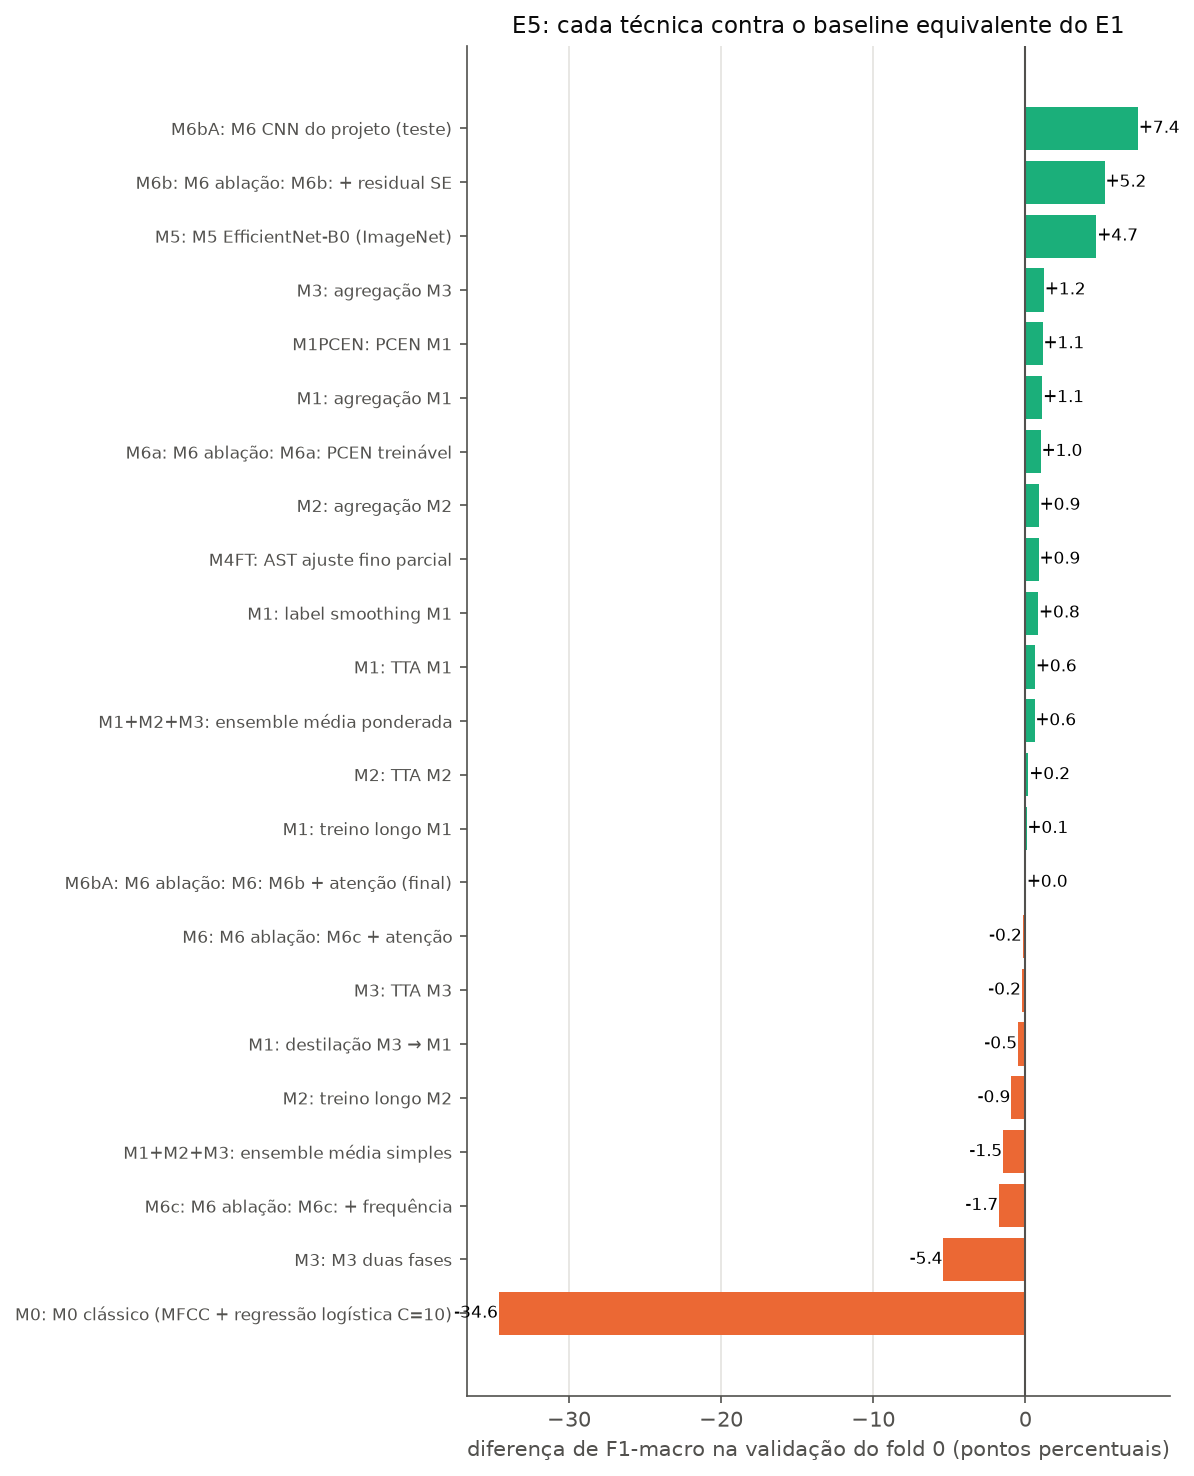

In [16]:
for tecnica, mudou in [("M3 label smoothing 0,1", "label smoothing 0,1 no M3 (testado no M1, seção 5.8)"),
                       ("M3 lr do corpo 3e-5", "lr do corpo 3e-5 (E1: 1e-4)"),
                       ("M3 lr do corpo 3e-4", "lr do corpo 3e-4 (E1: 1e-4)"),
                       ("divisão por autor M3", "StratifiedGroupKFold por autor com o M3")]:
    if mh.tabela().query("tecnica == @tecnica").empty or pd.isna(mh.tabela().query("tecnica == @tecnica")["val_f1"]).all():
        mh.registrar(tecnica=tecnica, modelo="M3", o_que_mudou=mudou, base="M3 E1 (fold 0)", minutos=None,
                     veredito="não executado", obs="cortado: ~50 min de GPU por treino do M3; priorizadas técnicas de famílias diferentes")
t5 = mh.tabela()
display(t5[["tecnica", "modelo", "o_que_mudou", "val_f1_base", "val_f1", "dif_val", "teste_f1_base", "teste_f1", "minutos", "veredito"]].round(3).set_index("tecnica"))
graficos.e5_barras(t5[~t5["veredito"].isin(["medição (robustez)"])], FIG / "e5_dif_val.png")
display(Image(FIG / "e5_dif_val.png"))

### Pesos finais atualizados

**O que:** refaz `checkpoints/finais/` agora que as variantes do E5 existem. Para cada tipo, fica o candidato de maior F1 na validação do fold 0 (E1 ou E5); o ensemble final é refeito sobre os finais, com pesos escolhidos na mesma validação. É a mesma função chamada no notebook 04, então os dois notebooks produzem os mesmos finais.

In [17]:
resumo_finais = finais.criar()
display(resumo_finais.set_index("final").round(3))

W1122 11:26:29.905000 26012 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


,origem,descricao,candidatos,val_f1,teste_f1,parametros
final,,,,,,
M1,checkpoints/M1PCEN_todas_s42_f0.pt,PCEN no lugar do log,5.0,0.869,0.902,3.935e+05
M2,checkpoints/M2_todas_s42_f0.pt,"E1, fold 0",2.0,0.848,0.869,3.746e+05
M3,checkpoints/M3_todas_s42_f0.pt,"E1, fold 0",2.0,0.923,0.939,7.971e+07
M4,checkpoints/M4_sem_s42_f0.pt,"E1, fold 0",1.0,0.839,0.823,1.538e+04
M4FT,checkpoints/M4FT_sem_s42_f0.pt,AST com os 2 últimos blocos ajustados,1.0,0.848,0.853,1.419e+07
M5,checkpoints/M5_todas_s42_f0.pt,EfficientNet-B0 ImageNet,1.0,0.904,0.923,4.033e+06
M6,checkpoints/M6bA_todas_s42_f0.pt,CNN do projeto: PCEN treinável + blocos residu...,4.0,0.932,0.914,3.358e+05
ensemble,M1×0.35 + M2×0.10 + M3×0.55,média ponderada das probabilidades por gravaçã...,NaN,0.934,0.950,NaN


## Conclusões do E5

**O que funcionou (confirmado no teste)**

| técnica | ganho no teste | custo |
|---|---|---|
| PCEN na entrada do M1 | +2,3 pontos (0,879 → 0,902); +2,6 a 0 dB | nenhum (uma camada sem parâmetros treináveis) |
| ensemble ponderado (final: M1 com PCEN + M2 + M3) | 0,939 → **0,950** | roda três modelos |
| calibração por temperatura | ECE de 0,23 → 0,03, sem mudar o F1 | nenhum |
| AST com os 2 últimos blocos ajustados | +3,0 pontos sobre o AST congelado (0,823 → 0,853) | 146 min de treino |
| M5 (ImageNet) como modelo de comparação | 0,923: +4,4 sobre o M1, 1,6 abaixo do M3 | 4 milhões de parâmetros, 24 min |
| **M6, a CNN do projeto** (PCEN treinável + blocos residuais SE) | M6b 0,924; M6 final (com atenção) 0,914; **0,920 a 0 dB**, no nível do M3 | 0,3 milhão de parâmetros, ~20 min, sem pré-treino |

**O que não funcionou:** TTA, agregação por máximo ou top-3, *label smoothing*, treino mais longo, destilação do M3 no M1, ajuste do M3 em duas fases e, no M6, o canal de frequência e a atenção nas janelas. Ficaram registrados com o mesmo detalhe na tabela.

**Medições (não são técnicas):**
- a linha de base clássica (M0) fica 33 pontos abaixo do M1;
- a divisão por gravador custa ~3,7 pontos ao M1: os números do E1 são algo otimistas, mas as comparações entre modelos se mantêm.

**Lição de método:** várias técnicas melhoraram a validação do fold 0 em ~1 ponto e **não** melhoraram o teste (agregação, *label smoothing*, treino longo, TTA). Com 480 gravações de validação, um ponto de F1 são ~5 gravações. Só os ganhos grandes (PCEN, ensemble, AST parcial) se confirmaram. Separar escolha (validação) e avaliação (teste, uma vez) evitou reportar como melhorias o que era ruído.

**Cortes por tempo de GPU (registrados como "não executado"):** M3 com *label smoothing*, M3 com taxas do corpo 3e-5 e 3e-4 e M3 na divisão por gravador (~50 min cada). A prioridade foi testar técnicas de famílias diferentes.